# Step 2: Train the models

We'll try three approaches on the dataset from Step 1, from simplest to smartest, and compare them:

| # | Method | Training? | Labels |
|---|---|---|---|
| 1 | **Baselines**: white-border rule + OCR | none | NWB, TLGW |
| 2 | **Small CNN** built from scratch | yes | both |
| 3 | **MobileNetV2** transfer learning + fine-tuning | yes | both |

**Colab tip:** turn on the free GPU first (*Runtime → Change runtime type → T4 GPU*). Training is then about 10x faster.

## 1. Setup

In [1]:
import os, sys
if 'google.colab' in sys.modules:
    !git clone -q https://github.com/sujatab1706-tech/my-project.git
    %cd my-project
    !apt-get -qq install -y tesseract-ocr > /dev/null
else:
    os.chdir('..')  # from notebooks/ to the project root (install Tesseract yourself: see README)
!pip install -q -r requirements.txt
sys.path.insert(0, 'src')

Colab forgets files when the runtime restarts, so rebuild the Step 1 dataset if it isn't there.
(This takes about 10 minutes. `--n 2000` is plenty for learning.)

In [2]:
if not os.path.exists('data/processed/labels.csv'):
    !python src/download_abo.py --n 2000 --listing-files 4 --out data/raw
    !python src/make_violations.py --raw data/raw --out data/processed

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
labels = pd.read_csv('data/processed/labels.csv')
labels.split.value_counts()

split
train    2540
val       544
test      542
Name: count, dtype: int64

## 2. Baselines (no training)
- **NWB rule:** what share of the edge pixels are white?
- **TLGW with OCR:** [Tesseract](https://github.com/tesseract-ocr/tesseract) is free software that reads text in images. If it confidently reads a word, we say "TLGW".

Each gives a score from 0 to 1, and we say "yes" when the score is 0.5 or more.

In [4]:
!python src/baselines.py --data data/processed --out results

  0%|                                                 | 0/1086 [00:00<?, ?it/s]

  0%|                                         | 1/1086 [00:00<02:49,  6.41it/s]

  0%|                                         | 2/1086 [00:00<02:21,  7.68it/s]

  0%|                                         | 3/1086 [00:00<02:19,  7.75it/s]

  0%|▏                                        | 4/1086 [00:00<02:26,  7.38it/s]

  0%|▏                                        | 5/1086 [00:00<02:21,  7.63it/s]

... (924 outputs left out)

100%|█████████████████████████████████████▉| 1083/1086 [02:18<00:00,  5.97it/s]

100%|█████████████████████████████████████▉| 1084/1086 [02:18<00:00,  6.37it/s]

100%|██████████████████████████████████████| 1086/1086 [02:18<00:00,  7.84it/s]


tlgw: test accuracy 0.677
nwb: test accuracy 0.987
saved results/baseline_predictions.csv


In [5]:
base = pd.read_csv('results/baseline_predictions.csv')
test_base = base[base.split == 'test']
pd.crosstab(test_base.tlgw, test_base.tlgw_pred, rownames=['true tlgw'], colnames=['OCR says tlgw'])

OCR says tlgw,0,1
true tlgw,,
0,276,88
1,87,91


OCR is **much weaker than you'd expect**. Look at its mistakes below:
- **False alarms:** many products have text printed *on the product itself*, like boxes, labels and phone cases. That's allowed! OCR can't tell "text on the product" from "text added on top of the photo".
- **Misses:** badges, small fonts, see-through watermarks and rotated text are hard for OCR to read.

This is why we need a model that learns what an *added* overlay looks like.

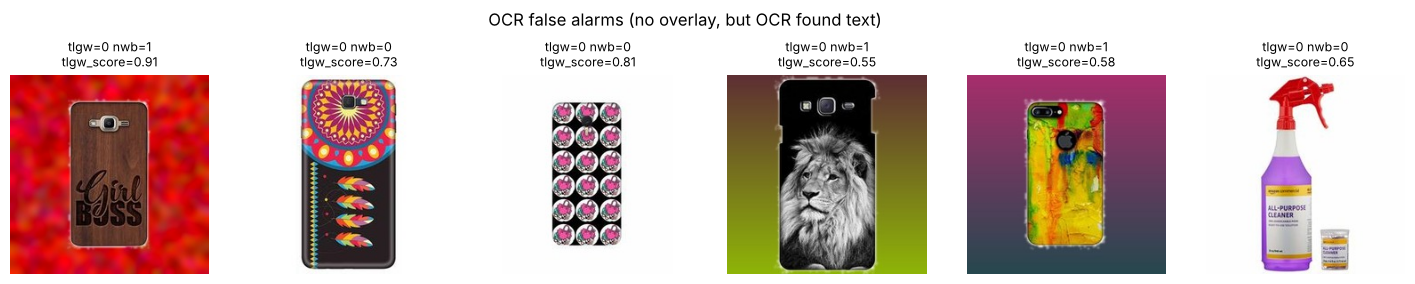

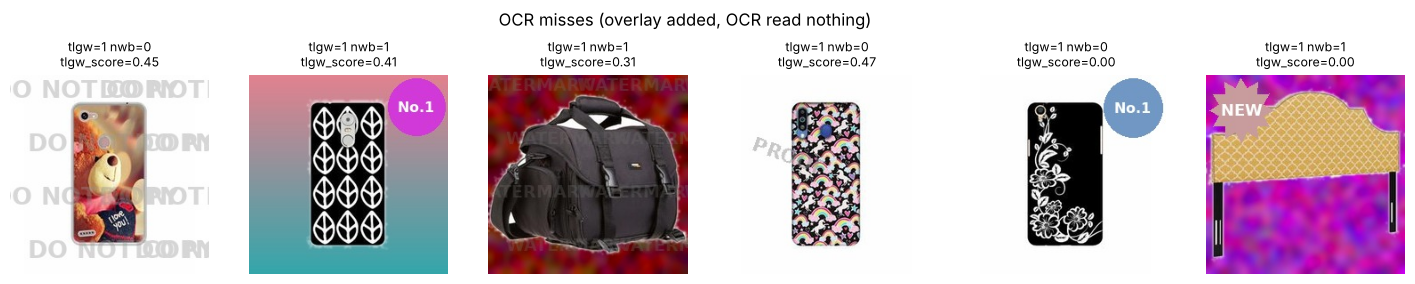

In [6]:
def show(df, title, prob_col=None, n=6):
    rows = df.sample(min(n, len(df)), random_state=0)
    if len(rows) == 0:
        print('nothing to show'); return
    fig, axes = plt.subplots(1, len(rows), figsize=(3 * len(rows), 3.4), squeeze=False)
    for ax, r in zip(axes[0], rows.itertuples()):
        ax.imshow(Image.open(f'data/processed/images/{r.file}'))
        t = f'tlgw={r.tlgw} nwb={r.nwb}'
        if prob_col: t += f'\n{prob_col}={getattr(r, prob_col):.2f}'
        ax.set_title(t, fontsize=9); ax.axis('off')
    fig.suptitle(title); plt.show()

show(test_base[(test_base.tlgw == 0) & (test_base.tlgw_pred == 1)], 'OCR false alarms (no overlay, but OCR found text)', 'tlgw_score')
show(test_base[(test_base.tlgw == 1) & (test_base.tlgw_pred == 0)], 'OCR misses (overlay added, OCR read nothing)', 'tlgw_score')

## 3. A small CNN from scratch
Three blocks of convolution + pooling, then 2 output neurons, each with a **sigmoid**, so we get one probability per label.
That's what makes this **multi-label**: the two answers are independent, and an image can be both TLGW and NWB.

The model starts knowing nothing and has only about 2,500 training images to learn from. Watch how it does on each label.

In [7]:
!python src/train_cnn.py --model small --epochs 15 --data data/processed --out results

I0000 00:00:1794858703.462899    9666 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794858703.463682    9666 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794858703.531765    9666 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794858704.610527    9666 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794858704.610860    9666 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


train 2540  val 544  test 542


E0000 00:00:1794858705.682837    9666 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/15


... (7 outputs left out)

80/80 - 10s - 128ms/step - acc: 0.8116 - loss: 0.3748 - val_acc: 0.8143 - val_loss: 0.3579
Epoch 9/15


80/80 - 11s - 136ms/step - acc: 0.8089 - loss: 0.3750 - val_acc: 0.8281 - val_loss: 0.3430
Epoch 10/15


80/80 - 11s - 132ms/step - acc: 0.8098 - loss: 0.3997 - val_acc: 0.8235 - val_loss: 0.3535


tlgw: test accuracy 0.662
nwb: test accuracy 0.974
saved model and predictions to results


### Learning curves
- `loss` going down = learning the training data
- `val_loss` going down too = learning things that also work on *new* images
- `val_loss` going **up** while `loss` goes down = **overfitting** (memorising). Early stopping stops training when that starts.

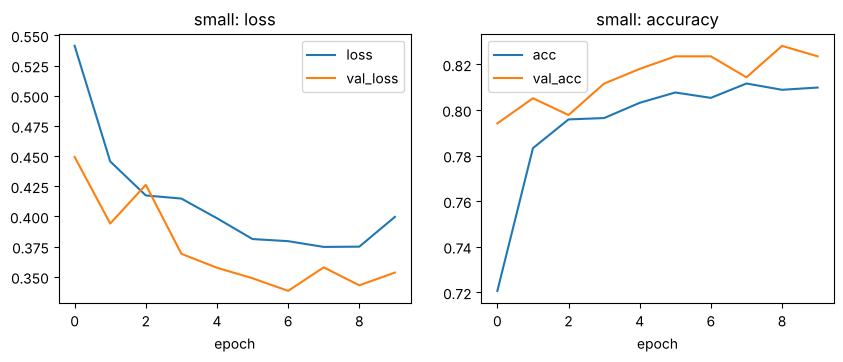

In [8]:
def plot_history(name):
    h = pd.read_csv(f'results/history_{name}.csv')
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
    h[['loss', 'val_loss']].plot(ax=a, title=f'{name}: loss'); h[['acc', 'val_acc']].plot(ax=b, title=f'{name}: accuracy')
    for ax in (a, b):
        ax.set_xlabel('epoch')
        if (h.phase == 2).any(): ax.axvline((h.phase == 1).sum() - 0.5, ls='--', c='gray')  # start of fine-tuning
    plt.show()
plot_history('small')

## 4. Transfer learning with MobileNetV2
MobileNetV2 was already trained on 1.4 million ImageNet photos, so it already knows edges, textures, letters and objects.
We reuse that knowledge in two phases:
1. **Freeze** the pretrained body and train only our new 2-neuron head (fast, learning rate 0.001).
2. **Fine-tune:** unfreeze the top 30 layers and train everything gently (learning rate 0.00001, 100x smaller), so we adjust the pretrained features instead of destroying them.

The dashed line in the plot marks where fine-tuning starts.

In [9]:
!python src/train_cnn.py --model mobilenet --epochs 10 --data data/processed --out results

I0000 00:00:1794858818.479597    9957 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794858818.480100    9957 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794858818.531616    9957 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794858819.760962    9957 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794858819.761259    9957 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


train 2540  val 544  test 542


E0000 00:00:1794858820.900017    9957 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
Epoch 1/10


... (19 outputs left out)

80/80 - 25s - 316ms/step - acc: 0.9844 - loss: 0.0441 - val_acc: 0.9531 - val_loss: 0.1330
Epoch 9/10


80/80 - 41s - 515ms/step - acc: 0.9858 - loss: 0.0434 - val_acc: 0.9614 - val_loss: 0.1191
Epoch 10/10


80/80 - 28s - 348ms/step - acc: 0.9898 - loss: 0.0342 - val_acc: 0.9504 - val_loss: 0.1353


tlgw: test accuracy 0.945
nwb: test accuracy 0.963
saved model and predictions to results


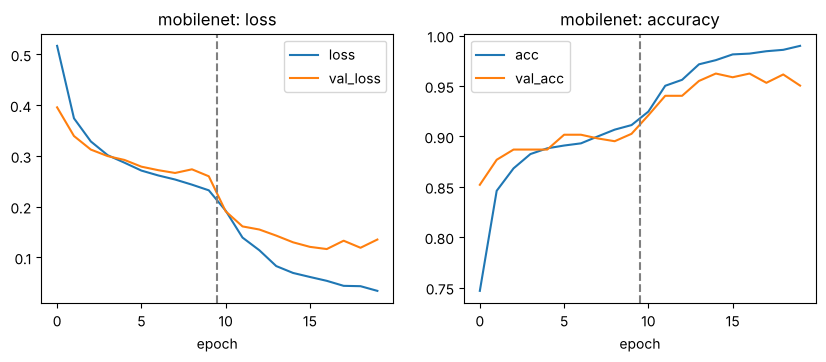

In [10]:
plot_history('mobilenet')

## 5. Compare all methods (test set, accuracy per label)

In [11]:
small = pd.read_csv('results/cnn_small_predictions.csv')
mob = pd.read_csv('results/cnn_mobilenet_predictions.csv')

def acc(df, label):
    t = df[df.split == 'test']
    return round((t[label] == t[f'{label}_pred']).mean(), 3)

test = labels[labels.split == 'test']
pd.DataFrame({
    'Always "no"': {'tlgw': round(1 - test.tlgw.mean(), 3), 'nwb': round(1 - test.nwb.mean(), 3)},
    'Rule / OCR':  {'tlgw': acc(base, 'tlgw'),  'nwb': acc(base, 'nwb')},
    'Small CNN':   {'tlgw': acc(small, 'tlgw'), 'nwb': acc(small, 'nwb')},
    'MobileNetV2': {'tlgw': acc(mob, 'tlgw'),   'nwb': acc(mob, 'nwb')},
})

,"Always ""no""",Rule / OCR,Small CNN,MobileNetV2
tlgw,0.672,0.677,0.662,0.945
nwb,0.677,0.987,0.974,0.963


How to read this table:
- **Always "no"** is a model that never flags anything. About two thirds of the images are fine for each label, so it scores about 67% without looking at a single pixel!
  **Any accuracy must be compared with this number.** (Step 3 shows better metrics that this trick can't fool.)
- **NWB:** the simple rule is very hard to beat on our data. Our fake backgrounds are obvious (big areas of colour), so even the small CNN learns it.
  You don't always need deep learning. In production you might use the rule *and* the CNN together.
- **TLGW:** this is the hard one. OCR barely beats "always no", and the small CNN, starting from zero with only about 2,500 training images, may not beat it at all.
  MobileNetV2 already knows what letters, edges and shapes look like, so it wins clearly. That's the power of transfer learning.

## 6. Where does MobileNetV2 still go wrong?

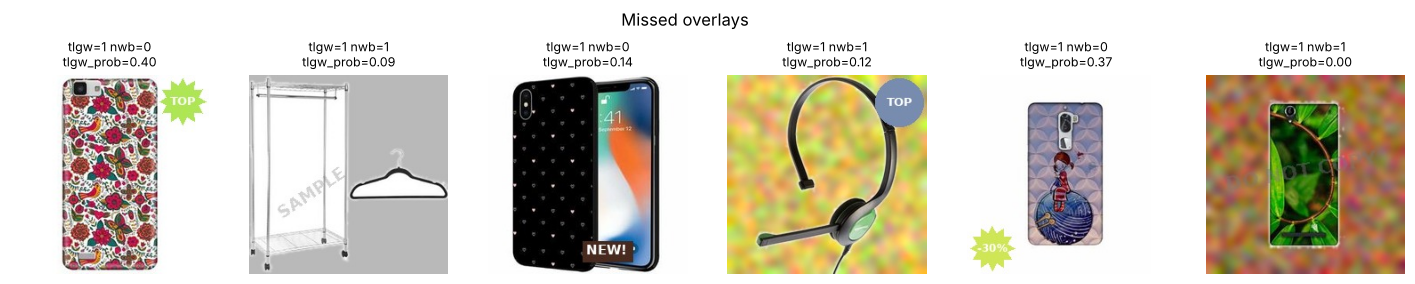

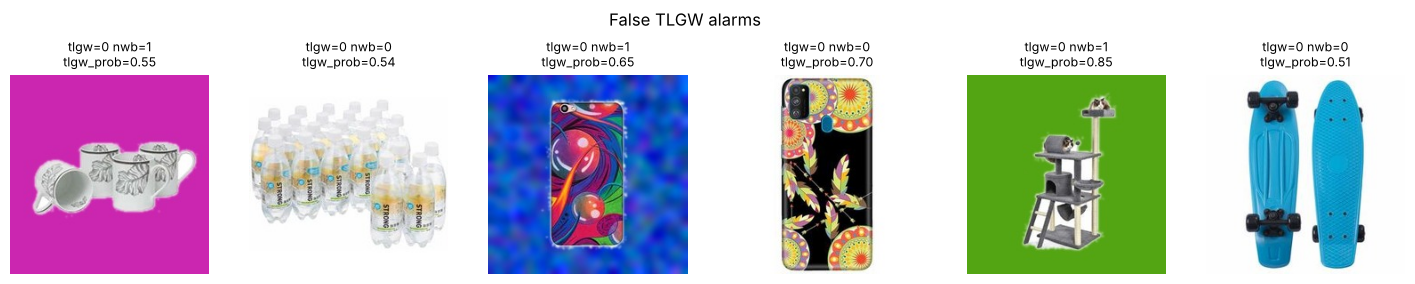

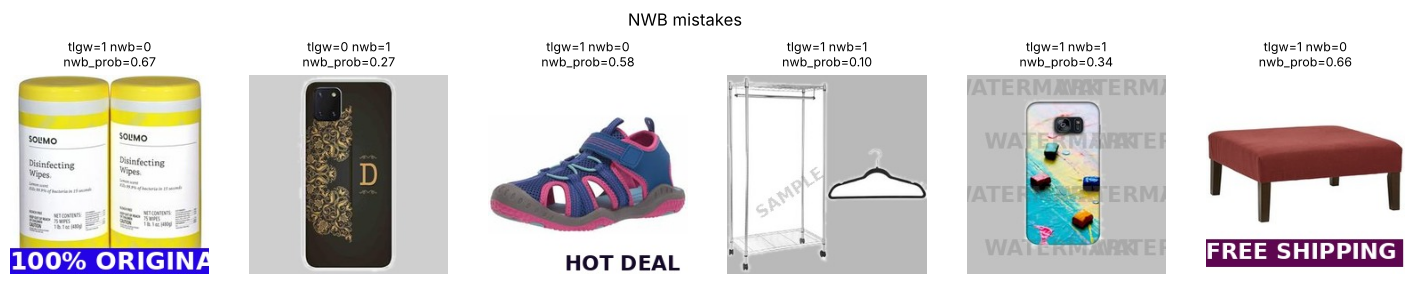

In [12]:
t = mob[mob.split == 'test']
show(t[(t.tlgw == 1) & (t.tlgw_pred == 0)], 'Missed overlays', 'tlgw_prob')
show(t[(t.tlgw == 0) & (t.tlgw_pred == 1)], 'False TLGW alarms', 'tlgw_prob')
show(t[t.nwb != t.nwb_pred], 'NWB mistakes', 'nwb_prob')

## What's next
Accuracy alone can fool you. A model that *never* flags anything would still look decent if most images are clean.
**Step 3** covers precision, recall, F1, confusion matrices and choosing a better threshold than 0.5 for each label.
The probabilities saved in `results/*_predictions.csv` are exactly what Step 3 needs.